**Explore the dataset and identify data types.**

In [2]:
import pandas as pd
df=pd.read_csv(r"C:\Users\venka\Downloads\online_retail.csv.zip")
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [3]:
df.shape

(541909, 8)

In [4]:
print(df.dtypes)

InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


**Handle missing values and remove duplicate records**

In [5]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
df["Description"]=df["Description"].fillna(df["Description"].mode()[0])
print(df["Description"])

0          WHITE HANGING HEART T-LIGHT HOLDER
1                         WHITE METAL LANTERN
2              CREAM CUPID HEARTS COAT HANGER
3         KNITTED UNION FLAG HOT WATER BOTTLE
4              RED WOOLLY HOTTIE WHITE HEART.
                         ...                 
541904            PACK OF 20 SPACEBOY NAPKINS
541905           CHILDREN'S APRON DOLLY GIRL 
541906          CHILDRENS CUTLERY DOLLY GIRL 
541907        CHILDRENS CUTLERY CIRCUS PARADE
541908          BAKING SET 9 PIECE RETROSPOT 
Name: Description, Length: 541909, dtype: object


In [7]:
#checking if there are any missing values is there or not
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
#removing duplicates
df=df.drop_duplicates()
print(df)

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

                InvoiceDate  UnitPrice  CustomerID         Country  
0     

**Remove invalid records (negative quantities and unit prices**

In [12]:
#checking if any invalid records are there or not
df = df[(df["Quantity"] < 0) | (df["UnitPrice"] < 0)]
print(df)

       InvoiceNo StockCode                       Description  Quantity  \
141      C536379         D                          Discount        -1   
154      C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235      C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236      C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237      C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   
...          ...       ...                               ...       ...   
540449   C581490     23144   ZINC T-LIGHT HOLDER STARS SMALL       -11   
541541   C581499         M                            Manual        -1   
541715   C581568     21258        VICTORIAN SEWING BOX LARGE        -5   
541716   C581569     84978  HANGING HEART JAR T-LIGHT HOLDER        -1   
541717   C581569     20979     36 PENCILS TUBE RED RETROSPOT        -5   

                InvoiceDate  UnitPrice  CustomerID         Country  
141     2010-12-01 09:41:00      27.50    

In [8]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print(df)

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

                InvoiceDate  UnitPrice  CustomerID         Country  
0     

**Create a new feature (TotalSales = Quantity × UnitPrice).**

In [9]:
df["TotalSales"]=df["Quantity"]*df["UnitPrice"]
print(df['TotalSales'])

0         15.30
1         20.34
2         22.00
3         20.34
4         20.34
          ...  
541904    10.20
541905    12.60
541906    16.60
541907    16.60
541908    14.85
Name: TotalSales, Length: 536641, dtype: float64


**Generate descriptive statistics for Quantity, Unit Price, and Total Sales**.

In [10]:
print(df["Quantity"].describe())
print("----"*20)
print(df["UnitPrice"].describe())
print("----"*20)
print(df["TotalSales"].describe())

count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64
--------------------------------------------------------------------------------
count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64
--------------------------------------------------------------------------------
count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: TotalSales, dtype: float64


**Perform monthly sales trend analysis**.

In [11]:
#converting invoice data(object dtype) to date and time dtype
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print(df["InvoiceDate"])

0        2010-12-01 08:26:00
1        2010-12-01 08:26:00
2        2010-12-01 08:26:00
3        2010-12-01 08:26:00
4        2010-12-01 08:26:00
                 ...        
541904   2011-12-09 12:50:00
541905   2011-12-09 12:50:00
541906   2011-12-09 12:50:00
541907   2011-12-09 12:50:00
541908   2011-12-09 12:50:00
Name: InvoiceDate, Length: 536641, dtype: datetime64[ns]


In [12]:
df["Month"] = df["InvoiceDate"].dt.month
print(df["Month"])

0         12
1         12
2         12
3         12
4         12
          ..
541904    12
541905    12
541906    12
541907    12
541908    12
Name: Month, Length: 536641, dtype: int32


In [13]:
print(df.groupby("Month")["TotalSales"].sum())

Month
1      558448.560
2      497026.410
3      682013.980
4      492367.841
5      722094.100
6      689977.230
7      680156.991
8      681386.460
9     1017596.682
10    1069368.230
11    1456145.800
12    1179424.670
Name: TotalSales, dtype: float64


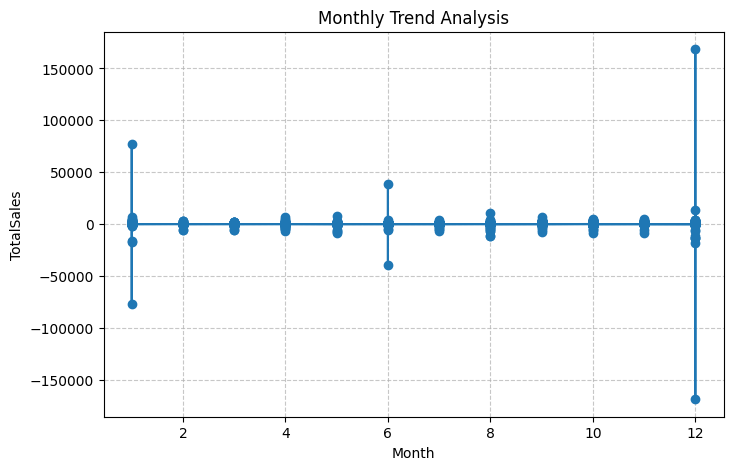

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(
    df["Month"],
    df["TotalSales"],
    marker="o")
plt.xlabel("Month")
plt.ylabel("TotalSales")
plt.title("Monthly Trend Analysis")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()


**Identify the top 10 best-selling products**

In [15]:
#converting Descriptive feature(object dtype) to String dtype
df["Description"] = df["Description"].astype("string")
print(df.dtypes)

InvoiceNo              object
StockCode              object
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
TotalSales            float64
Month                   int32
dtype: object


In [19]:
top10 = (df.groupby("Description")["Quantity"].sum().
         reset_index()
        .sort_values(by="Quantity",ascending=False)         
        .head(10).reset_index(drop=True)                             
)

print(top10)




                          Description  Quantity
0   WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
1             JUMBO BAG RED RETROSPOT     47260
2                      POPCORN HOLDER     36322
3       ASSORTED COLOUR BIRD ORNAMENT     36282
4     PACK OF 72 RETROSPOT CAKE CASES     36016
5                  RABBIT NIGHT LIGHT     30631
6             MINI PAINT SET VINTAGE      26437
7          PACK OF 12 LONDON TISSUES      26299
8  PACK OF 60 PINK PAISLEY CAKE CASES     24719
9     VICTORIAN GLASS HANGING T-LIGHT     23825


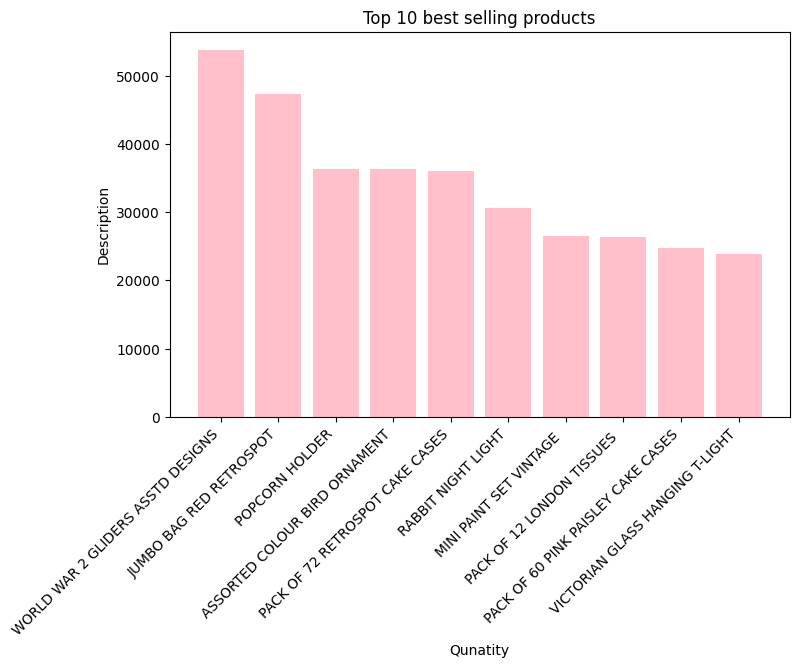

In [25]:
#visualising by using bar graph
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(top10["Description"],top10["Quantity"],color="pink")
plt.xlabel("Qunatity")
plt.ylabel("Description")
plt.title("Top 10 best selling products")
plt.xticks(rotation=45,ha="right")
plt.show()

**Analyze sales by country.**

In [23]:
#grouping total sales according to their Country
country_sales=df.groupby("Country")["TotalSales"].sum().reset_index().sort_values(by="TotalSales",ascending=False).reset_index(drop=True)
print(country_sales)

                 Country   TotalSales
0         United Kingdom  8167128.184
1            Netherlands   284661.540
2                   EIRE   262993.380
3                Germany   221509.470
4                 France   197317.110
5              Australia   137009.770
6            Switzerland    56363.050
7                  Spain    54756.030
8                Belgium    40910.960
9                 Sweden    36585.410
10                 Japan    35340.620
11                Norway    35163.460
12              Portugal    29302.970
13               Finland    22326.740
14       Channel Islands    20076.390
15               Denmark    18768.140
16                 Italy    16890.510
17                Cyprus    12858.760
18               Austria    10154.320
19             Hong Kong     9908.240
20             Singapore     9120.390
21                Israel     7901.970
22                Poland     7213.140
23           Unspecified     4740.940
24                Greece     4710.520
25          

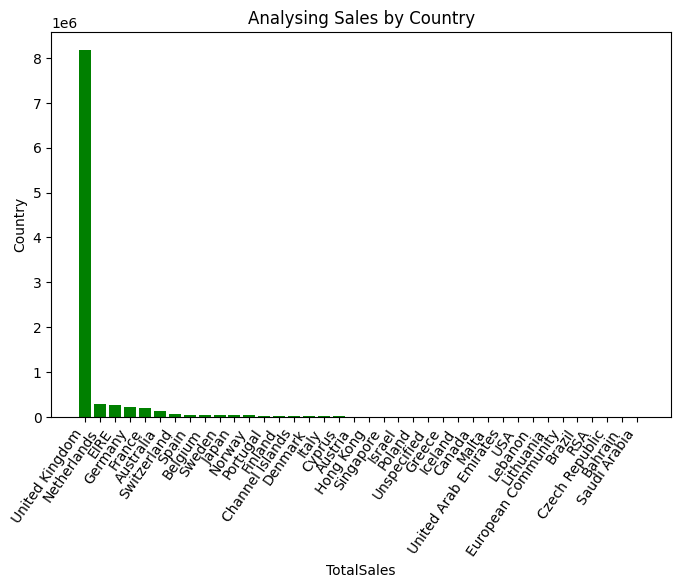

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(country_sales["Country"],country_sales["TotalSales"],color="green")
plt.xlabel("TotalSales")
plt.ylabel("Country")
plt.title("Analysing Sales by Country")
plt.xticks(rotation=55,ha="right")
plt.show()

**Compute the correlation among Quantity, Unit Price, and Total Sales**

In [63]:
corr_matrix = df[["Quantity", "UnitPrice", "TotalSales"]].corr()
print(corr_matrix)


            Quantity  UnitPrice  TotalSales
Quantity    1.000000  -0.003788    0.907402
UnitPrice  -0.003788   1.000000    0.137381
TotalSales  0.907402   0.137381    1.000000


In [66]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


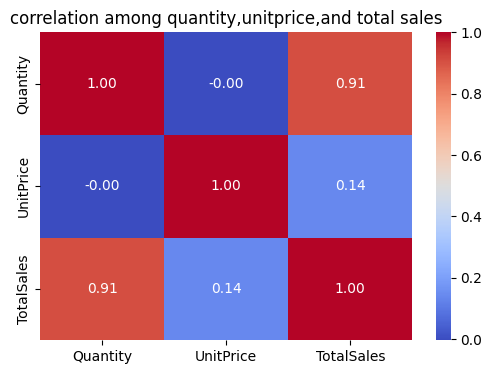

In [68]:
#visualtion of correlation using heatmap
import seaborn as sns 
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("correlation among quantity,unitprice,and total sales")
plt.show()

**Detect outliers in Total Sales using a box plot**

In [71]:
Q1 = df["TotalSales"].quantile(0.25)
Q3 = df["TotalSales"].quantile(0.75)

IQR = Q3 - Q1

outliers = df[
    (df["TotalSales"] < Q1 - 1.5 * IQR) |
    (df["TotalSales"] > Q3 + 1.5 * IQR)
]

print(outliers[["TotalSales"]])

        TotalSales
9            54.08
26           90.00
27           90.00
28           45.00
31           40.80
...            ...
541866       66.60
541867       51.84
541868       88.80
541892      214.80
541893       70.80

[42624 rows x 1 columns]


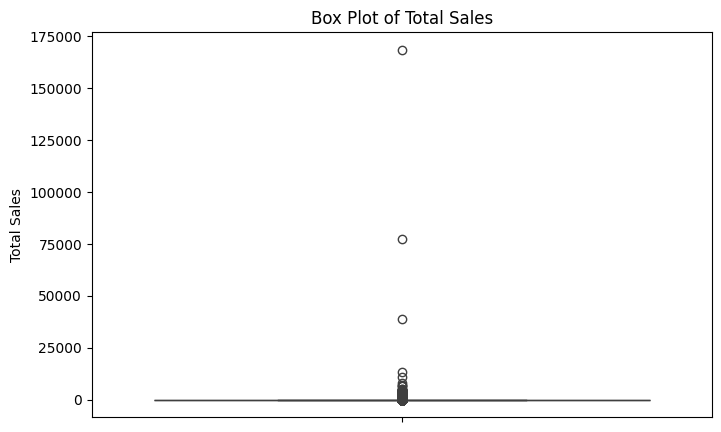

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.boxplot(y=df["TotalSales"])

plt.title("Box Plot of Total Sales")
plt.ylabel("Total Sales")

plt.show()

**Visualize the relationship between Quantity and Total Sales using a scatter plot**

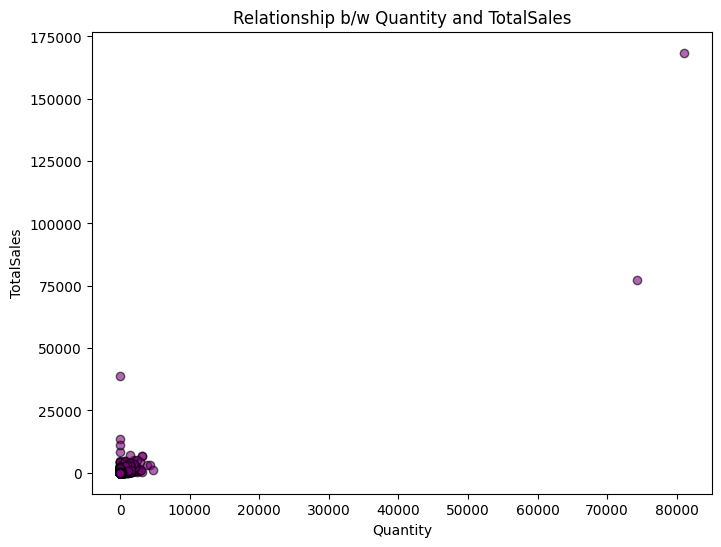

In [72]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(df["Quantity"],df["TotalSales"],color="purple",alpha=0.6,edgecolor="k")
plt.xlabel("Quantity")
plt.ylabel("TotalSales")
plt.title("Relationship b/w Quantity and TotalSales")
plt.show()

**Summarize the business insights obtained from the analysis**